# **Proyecto Análisis Tienda Video Juegos Ice**  

### * Analisi precentado por Cesar Rodriguez *

In [ ]:
##carga de libreias y datos para su priumera exploracion y diagnostico 

import pandas as pd
import numpy as np
from scipy import stats as st
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
video_juegos = pd.read_csv('/datasets/games.csv')

## * Primer acercamiento a los datos *

In [ ]:
def funcion_diagnostico_inicial(video_juegos):
    print('Estructura del Data Frame')
    print(video_juegos.info())
    print()
    print('Muestra del Data Frame')
    print(video_juegos.sample())
 
funcion_diagnostico_inicial(video_juegos)   

Estructura del Data Frame
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB
None

Muestra del Data Frame
                        Name Platform  Year_of_Release     Genre  NA_sales  \
723  Dissidia: Final Fantasy      PSP           2008.0  Fighting      0.51   

     EU_sales  JP_sales  Othe

#### En este primer acercamiento podemos ver la precencia de valores ausentes en varias columnas, 'name', 'year_of_release', 'genre', 'critic_score', 'user_score' y 'rating'.

#### Los nombres de las columnas deben ser cambiados a minusculas, buscar valores ausentes en cada columna, encontrar como manejarlos. 

## Paso numero 2 preparar los datos 

In [ ]:
# Conversion de los nombres de columna  a minusculas 
video_juegos.columns = [x.lower() for x in video_juegos.columns]
video_juegos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


#### Conversión de los datos, a el tipo correcto para el analisis.

In [ ]:
print(video_juegos['year_of_release'].isna().sum())
video_juegos['year_of_release'] = video_juegos['year_of_release'].astype('Int64')

# Cuántos valores ausentes hay
print("Valores ausentes en year_of_release:", video_juegos['year_of_release'].isna().sum())

# Algunos ejemplos de juegos sin año
juegos_sin_año = video_juegos[video_juegos['year_of_release'].isna()]
print("\nPrimeros 5 juegos sin año de lanzamiento:")
print(juegos_sin_año[['name', 'platform', 'year_of_release', 'genre']].head())
# crear la columna 'año ausente' 
video_juegos['año_ausente'] = video_juegos['year_of_release'].isna()
video_juegos['año_ausente'].value_counts(dropna=False)

269
Valores ausentes en year_of_release: 269

Primeros 5 juegos sin año de lanzamiento:
                           name platform  year_of_release     genre
183             Madden NFL 2004      PS2             <NA>    Sports
377            FIFA Soccer 2004      PS2             <NA>    Sports
456  LEGO Batman: The Videogame      Wii             <NA>    Action
475  wwe Smackdown vs. Raw 2006      PS2             <NA>  Fighting
609              Space Invaders     2600             <NA>   Shooter


False    16446
True       269
Name: año_ausente, dtype: int64

In [ ]:
total_filas = 16750
valores_ausentes = 269
porcentaje = (valores_ausentes / total_filas) * 100
print(f"El porcentaje de valores ausentes es: {porcentaje: .2f}%")

El porcentaje de valores ausentes es:  1.61%


#### Se creo la columna 'año ausente' para almacenar los juegos sin año de lanzamiento, y tamambien se ajusto el tipo de dato a entero para su uso en el analisis, teniendo en cuenta que el porcentaje de valores ausentes es apenas del 1.61 % , decidi mantenerlos asi, ya que en mi opinion, no tendran un impacto significativo en el objetivo de este anlisis

In [ ]:
# valores unicos en la columna 'user_score'
print('Valores unicos en la columna user_score (primeros 20):')
print(video_juegos['user_score'].value_counts().head(20))

# numero de valores 'tbd'
print("Valores 'tbd':")
print((video_juegos['user_score'] == 'tbd').sum())

# que juegos fueron 'tbd'originalmente 
video_juegos['user_score_was_tbd'] = video_juegos['user_score'] == 'tbd'

# remplazo de 'tbd' pos NaN 
video_juegos['user_score'] = video_juegos['user_score'].replace('tbd' , np.nan)

# conversión a valor correcto float
video_juegos['user_score'] = video_juegos['user_score'].astype('float')

print("Tipo de datos de user_score:", video_juegos['user_score'].dtype)
print("Valores NaN en user_score:", video_juegos['user_score'].isna().sum())
print("Valores que eran 'tbd':", video_juegos['user_score_was_tbd'].sum())
print("¿Coinciden los números?", video_juegos['user_score'].isna().sum() >= video_juegos['user_score_was_tbd'].sum())

Valores unicos en la columna user_score (primeros 20):
tbd    2424
7.8     324
8       290
8.2     282
8.3     254
8.5     253
7.5     251
7.9     249
8.1     244
7.7     240
7.3     236
8.4     223
7.6     220
7       220
7.4     215
8.6     211
6.8     197
8.7     188
8.8     186
7.1     180
Name: user_score, dtype: int64
Valores 'tbd':
2424
Tipo de datos de user_score: float64
Valores NaN en user_score: 9125
Valores que eran 'tbd': 2424
¿Coinciden los números? True


#### Se creo la columna 'user_score_was_tbd' y se remplazaron estos valores con NaN, ademas de los valores ausentes dentro de la columna, al sumarlos las cantidades coinsiden, y dejamos el typo de dato en float.

In [ ]:
print(video_juegos['name'].isna().sum())

2


#### Dos valores ausentes significan nada, asi que podemos trabajar al rededor de ellos sin ningn problema 

In [ ]:
print(video_juegos['genre'].isna().sum())

2


#### Dos valores ausentes significan nada, asi que podemos trabajar al rededor de ellos sin ningn problema 

In [ ]:
print(video_juegos['critic_score'].isna().sum())
print(video_juegos['critic_score'].head(20))

8578
0     76.0
1      NaN
2     82.0
3     80.0
4      NaN
5      NaN
6     89.0
7     58.0
8     87.0
9      NaN
10     NaN
11    91.0
12     NaN
13    80.0
14    61.0
15    80.0
16    97.0
17    95.0
18     NaN
19    77.0
Name: critic_score, dtype: float64


In [ ]:
video_juegos['critic_score'] = video_juegos['critic_score'].replace(np.nan, 'unknown')
print(video_juegos.head())
print(video_juegos['critic_score'].isna().sum())


                       name platform  year_of_release         genre  na_sales  \
0                Wii Sports      Wii             2006        Sports     41.36   
1         Super Mario Bros.      NES             1985      Platform     29.08   
2            Mario Kart Wii      Wii             2008        Racing     15.68   
3         Wii Sports Resort      Wii             2009        Sports     15.61   
4  Pokemon Red/Pokemon Blue       GB             1996  Role-Playing     11.27   

   eu_sales  jp_sales  other_sales critic_score  user_score rating  \
0     28.96      3.77         8.45         76.0         8.0      E   
1      3.58      6.81         0.77      unknown         NaN    NaN   
2     12.76      3.79         3.29         82.0         8.3      E   
3     10.93      3.28         2.95         80.0         8.0      E   
4      8.89     10.22         1.00      unknown         NaN    NaN   

   año_ausente  user_score_was_tbd  
0        False               False  
1        False    

#### En esta columna el porcentaje de valores ausentes es altisimo, mas del 51%, la falta de estos datos puede deverse a que el juego nunca salio a la venta, no fue terminado o era de un aporductora independeinte y por eso no llego a manos de los criticos, al pensar en este escenario, rempalce esos valores con 'unknown' para facilitar el manejo de estos datos en el analisis.

In [ ]:
print(video_juegos['rating'].head())
video_juegos['rating'] = video_juegos['rating'].replace(np.nan, 'unknown')
print(video_juegos.head())
print(video_juegos['rating'].isna().sum())


0      E
1    NaN
2      E
3      E
4    NaN
Name: rating, dtype: object
                       name platform  year_of_release         genre  na_sales  \
0                Wii Sports      Wii             2006        Sports     41.36   
1         Super Mario Bros.      NES             1985      Platform     29.08   
2            Mario Kart Wii      Wii             2008        Racing     15.68   
3         Wii Sports Resort      Wii             2009        Sports     15.61   
4  Pokemon Red/Pokemon Blue       GB             1996  Role-Playing     11.27   

   eu_sales  jp_sales  other_sales critic_score  user_score   rating  \
0     28.96      3.77         8.45         76.0         8.0        E   
1      3.58      6.81         0.77      unknown         NaN  unknown   
2     12.76      3.79         3.29         82.0         8.3        E   
3     10.93      3.28         2.95         80.0         8.0        E   
4      8.89     10.22         1.00      unknown         NaN  unknown   

   año_

#### En la columna 'rating' se replazaron los valores ausentes por 'unknown' ya que contamos con titulos de años anteriores a 1994 que fue cuando la Entretaiment Software Ratin Board (ESRB), fue creada para aplicar clasificaciones a los video juegos en America.

### Calculo de las ventas totales por videojuego 

In [ ]:
video_juegos['total_sales'] = video_juegos[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].sum(axis=1)

In [ ]:
video_juegos.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,año_ausente,user_score_was_tbd,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,False,False,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,unknown,NaN,unknown,False,False,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,False,False,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,False,False,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,unknown,NaN,unknown,False,False,31.38


## Paso numero 3 Analisis de los datos 

In [ ]:
# filtrado de plataformas con mayor venta por año 

top_plataformas = video_juegos.groupby('platform')['total_sales'].sum().sort_values(ascending=False).head(5)
print("Top 5 plataformas por ventas totales:")
print(top_plataformas)


Top 5 plataformas por ventas totales:
platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
Name: total_sales, dtype: float64


In [ ]:

top_plataformas = ['PS2', 'X360', 'PS3', 'Wii', 'DS']  
años = [2013.0, 2014.0, 2015.0, 2016.0]

for plataforma in top_plataformas:
    print(f"\n--- {plataforma} ---")
    for año in años:
        datos = video_juegos[(video_juegos['year_of_release'] == año) & 
                            (video_juegos['platform'] == plataforma)]
        ventas = datos['total_sales'].sum()
        print(f"{año}: {ventas:.2f} millones")



--- PS2 ---
2013.0: 0.00 millones
2014.0: 0.00 millones
2015.0: 0.00 millones
2016.0: 0.00 millones

--- X360 ---
2013.0: 88.58 millones
2014.0: 34.74 millones
2015.0: 11.96 millones
2016.0: 1.52 millones

--- PS3 ---
2013.0: 113.25 millones
2014.0: 47.76 millones
2015.0: 16.82 millones
2016.0: 3.60 millones

--- Wii ---
2013.0: 8.59 millones
2014.0: 3.75 millones
2015.0: 1.14 millones
2016.0: 0.18 millones

--- DS ---
2013.0: 1.54 millones
2014.0: 0.00 millones
2015.0: 0.00 millones
2016.0: 0.00 millones


## Aun que en el DtaSet esta son las plataformas con mas apariciones y reultados, PS2 tiene un ranquin en 0 de ventas, esto demuestra como un producto que en su momento fue lider puede ser revazado por la inovacion.

In [ ]:
plataformas_potenciales = ['PS4', 'XOne', 'GBA', 'PC', 'WiiU']  
años = [2013.0, 2014.0, 2015.0, 2016.0]

for plataforma in plataformas_potenciales:
    print(f"\n--- {plataforma} ---")
    for año in años:
        datos = video_juegos[(video_juegos['year_of_release'] == año) & 
                            (video_juegos['platform'] == plataforma)]
        ventas = datos['total_sales'].sum()
        print(f"{año}: {ventas:.2f} millones")


--- PS4 ---
2013.0: 25.99 millones
2014.0: 100.00 millones
2015.0: 118.90 millones
2016.0: 69.25 millones

--- XOne ---
2013.0: 18.96 millones
2014.0: 54.07 millones
2015.0: 60.14 millones
2016.0: 26.15 millones

--- GBA ---
2013.0: 0.00 millones
2014.0: 0.00 millones
2015.0: 0.00 millones
2016.0: 0.00 millones

--- PC ---
2013.0: 12.38 millones
2014.0: 13.28 millones
2015.0: 8.52 millones
2016.0: 5.25 millones

--- WiiU ---
2013.0: 21.65 millones
2014.0: 22.03 millones
2015.0: 16.35 millones
2016.0: 4.60 millones


### Con este comparativo queiro incluir consolas que considero mas actuales y que tambien tienen una buena cantidad de datos para analizar las tendencias que estamos busando 

In [ ]:
video_juegos['year_of_release'].min()

1980

In [ ]:
video_juegos['year_of_release'].max()

2016

In [ ]:
# Estadísticas generales
print(f"Rango de años: {video_juegos['year_of_release'].min()} - {video_juegos['year_of_release'].max()}")
print(f"Total de juegos con año válido: {video_juegos['year_of_release'].notna().sum()}")
print(f"Juegos sin año: {video_juegos['year_of_release'].isna().sum()}")

Rango de años: 1980 - 2016
Total de juegos con año válido: 16446
Juegos sin año: 269


In [ ]:
# Contar juegos por año y ver la evolución
juegos_por_año = video_juegos['year_of_release'].value_counts().sort_index()
print("Juegos lanzados por año (primeros 37 años):")
print(juegos_por_año.head(37))
print("\nJuegos lanzados por año (últimos 37 años):")

Juegos lanzados por año (primeros 37 años):
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      62
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: year_of_release, dtype: Int64

Juegos lanzados por año (últimos 37 años):


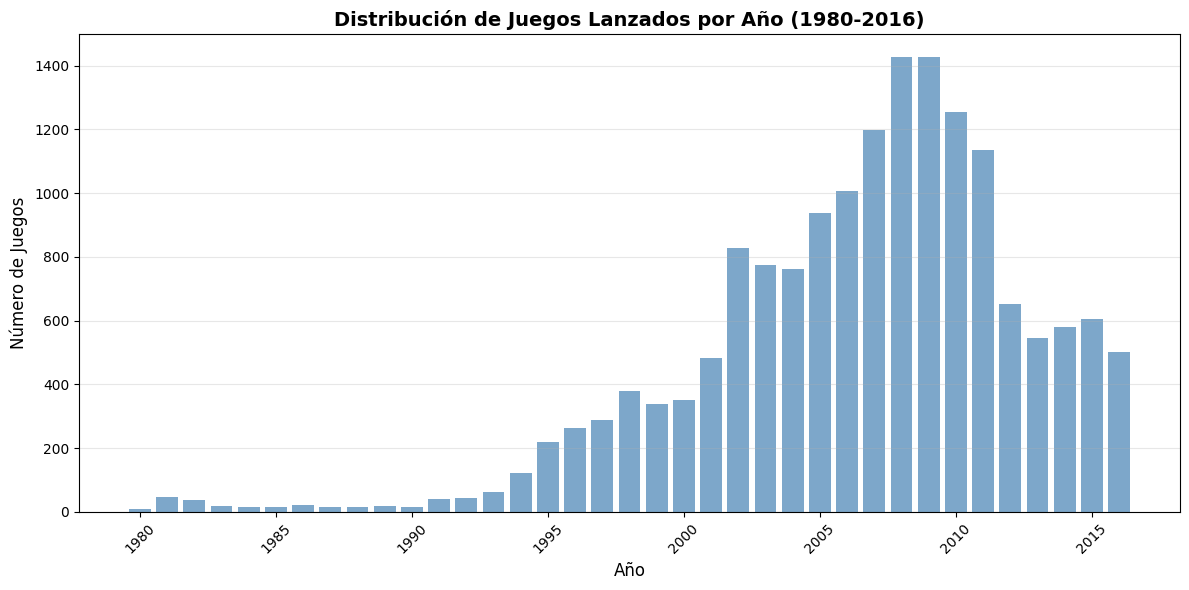

In [ ]:
# Gráfico de barras por décadas
plt.figure(figsize=(12, 6))
bars = plt.bar(juegos_por_año.index, juegos_por_año.values, alpha=0.7, color='steelblue')
plt.title('Distribución de Juegos Lanzados por Año (1980-2016)', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Número de Juegos', fontsize=12)
plt.xticks(range(1980, 2017, 5), rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Determine un promedio de 2013 a 2016 para obcervar el comportamiento del mercado y tener mas claro el panorama para poder entender como podria ser la tendencia, crecimiento y buscar las potenciales marcas y consolas que seran las lideres en ventas.

In [ ]:
# nombre de las consolas y frecuencia de aparicion en el data set 
video_juegos['platform'].value_counts().head(5)

PS2     2161
DS      2151
PS3     1331
Wii     1320
X360    1262
Name: platform, dtype: int64

In [ ]:
# Ventas TOTALES por plataforma 
ventas_por_plataforma = video_juegos.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print(ventas_por_plataforma.head(10))

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64


In [ ]:
# Promedio por plataforma para comparar
promedio_por_plataforma = video_juegos.groupby('platform')['total_sales'].mean().sort_values(ascending=False)
print(promedio_por_plataforma.head(10))

platform
GB      2.606735
NES     2.561735
GEN     1.061034
SNES    0.836987
PS4     0.801378
X360    0.769746
2600    0.729173
PS3     0.705973
Wii     0.687508
N64     0.685517
Name: total_sales, dtype: float64


In [ ]:
# cuántos juegos hay por año
for año in años:
    total_juegos = len(video_juegos[video_juegos['year_of_release'] == año])
    print(f"Año {año}: {total_juegos} juegos")

Año 2013.0: 544 juegos
Año 2014.0: 581 juegos
Año 2015.0: 606 juegos
Año 2016.0: 502 juegos


In [ ]:
# Ventas totales por año
for año in años:
    datos_año = video_juegos[video_juegos['year_of_release'] == año]
    ventas_totales = datos_año['total_sales'].sum()
    print(f"Año {año}: {ventas_totales:.2f} millones")

Año 2013.0: 361.24 millones
Año 2014.0: 331.53 millones
Año 2015.0: 267.98 millones
Año 2016.0: 129.94 millones


In [ ]:
# Obtener el top 5 de plataformas 
top_plataformas = video_juegos.groupby('platform')['total_sales'].sum().sort_values(ascending=False).head(5)
top_5_populares = top_plataformas.index.tolist()
print("Plataformas a incluir:", top_5_populares)

datos_filtrados = video_juegos[video_juegos['platform'].isin(top_5_populares)]
print(f"Datos originales: {len(video_juegos)} juegos")
print(f"Datos filtrados: {len(datos_filtrados)} juegos")

Plataformas a incluir: ['PS2', 'X360', 'PS3', 'Wii', 'DS']
Datos originales: 16715 juegos
Datos filtrados: 8225 juegos


In [ ]:
# Identificar valores atípicos extremos
print("Juegos con ventas > 20 millones:")
juegos_extremos = datos_filtrados[datos_filtrados['total_sales'] > 20]
print(f"Cantidad: {len(juegos_extremos)}")
print(juegos_extremos[['name', 'platform', 'total_sales']].sort_values('total_sales', ascending=False))

Juegos con ventas > 20 millones:
Cantidad: 14
                                            name platform  total_sales
0                                     Wii Sports      Wii        82.54
2                                 Mario Kart Wii      Wii        35.52
3                              Wii Sports Resort      Wii        32.77
6                          New Super Mario Bros.       DS        29.80
7                                       Wii Play      Wii        28.91
8                      New Super Mario Bros. Wii      Wii        28.32
10                                    Nintendogs       DS        24.67
11                                 Mario Kart DS       DS        23.21
13                                       Wii Fit      Wii        22.70
14                            Kinect Adventures!     X360        21.82
15                                  Wii Fit Plus      Wii        21.80
16                            Grand Theft Auto V      PS3        21.05
17                 Grand Theft 

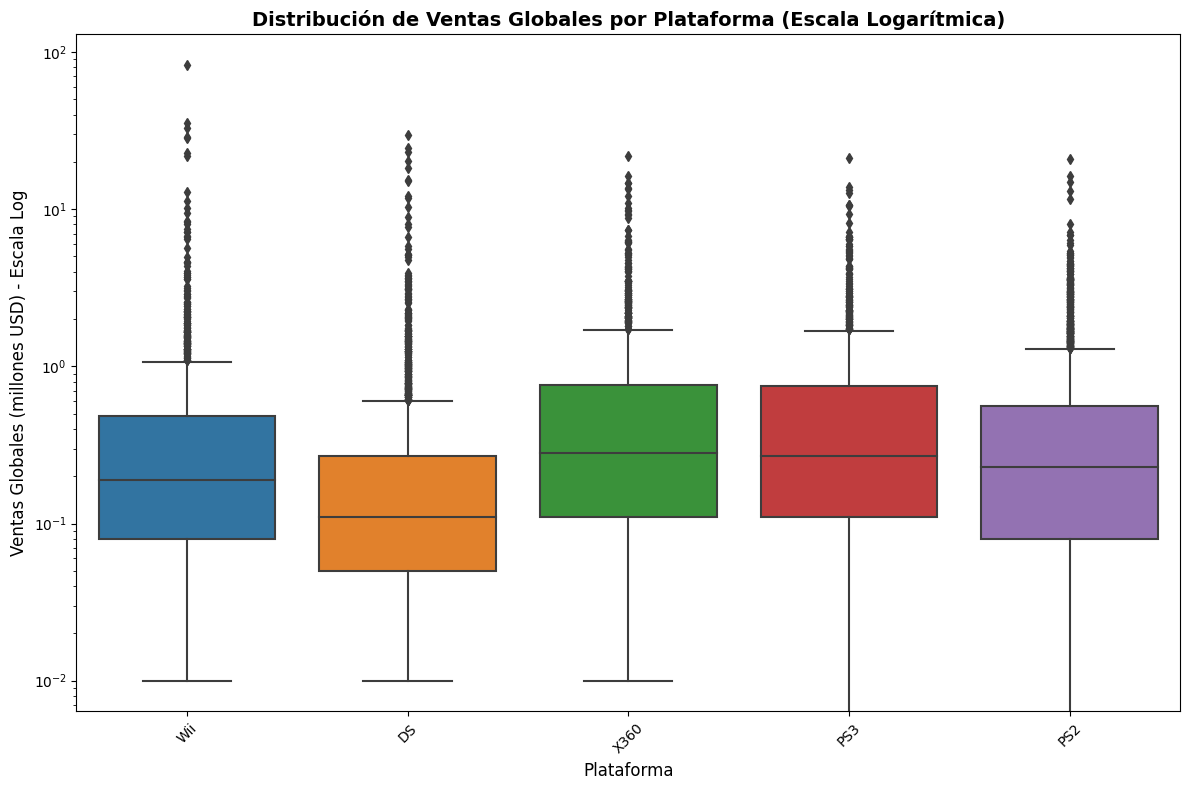

In [ ]:
plt.figure(figsize=(12, 8))

# Boxplot con escala logarítmica
ax = sns.boxplot(data=datos_filtrados, x='platform', y='total_sales')
plt.yscale('log')  # Escala logarítmica

plt.title('Distribución de Ventas Globales por Plataforma (Escala Logarítmica)', fontsize=14, fontweight='bold')
plt.xlabel('Plataforma', fontsize=12)
plt.ylabel('Ventas Globales (millones USD) - Escala Log', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Las consolas de Sony PS2 Y PS3 estan dentro de las plataformas con mas ventas, cabe mencionas que la consolas de Microsofy la Xbox360 esta a la par de PS3, nintendo se mantienen en el mercado pero con ventas por debajo de la tenencia que es x360, cabe mencionar que las ventas de PS2 fueron a la baja pero en este DataSet aparece como lider. 

In [ ]:
top_platforms = datos_filtrados['platform'].value_counts().head()
print("Top 5 plataformas por cantidad de juegos:")
print(top_platforms)
print("\nVentas promedio por plataforma:")
ventas_promedio = datos_filtrados.groupby('platform')['total_sales'].mean().sort_values(ascending=False)
print(ventas_promedio.head())

Top 5 plataformas por cantidad de juegos:
PS2     2161
DS      2151
PS3     1331
Wii     1320
X360    1262
Name: platform, dtype: int64

Ventas promedio por plataforma:
platform
X360    0.769746
PS3     0.705973
Wii     0.687508
PS2     0.581106
DS      0.374765
Name: total_sales, dtype: float64


In [ ]:
ps4_data = video_juegos[video_juegos['platform'] == 'PS4'].copy()

print(f"Juegos de PS4 en el dataset: {len(ps4_data)}")
print(f"Rango de años: {ps4_data['year_of_release'].min()} - {ps4_data['year_of_release'].max()}")

# Disponibilidad de datos de reseñas
print(f"\nDatos de reseñas disponibles:")
print(f"User Score: {ps4_data['user_score'].notna().sum()} juegos")
print(f"Critic Score: {ps4_data['critic_score'].notna().sum()} juegos")

# Algunos ejemplos
print(f"\nPrimeros 5 juegos con datos completos:")
ps4_completo = ps4_data.dropna(subset=['user_score', 'critic_score', 'total_sales'])
print(ps4_completo[['name', 'total_sales', 'user_score', 'critic_score']].head())

Juegos de PS4 en el dataset: 392
Rango de años: 2013 - 2016

Datos de reseñas disponibles:
User Score: 257 juegos
Critic Score: 392 juegos

Primeros 5 juegos con datos completos:
                               name  total_sales  user_score critic_score
42               Grand Theft Auto V        12.62         8.3         97.0
77                          FIFA 16         8.58         4.3         82.0
92   Call of Duty: Advanced Warfare         7.66         5.7         83.0
94                          FIFA 17         7.60         5.0         85.0
105                       Fallout 4         7.17         6.5         87.0


### Los pormedios de la critica son algo interesantes, tienen una buena venta en los juegos ranqueados altos, pero en la crituca del usuario los juegos con calificacion baja son los que mayor venta tienen, quiza por los costos, o por que la mayoria de los juegadores aun no juegan dichos titulos, por que cabe mencionar que los criticos y profecionales del gaming siempre tienen acceso a los juegos primero.

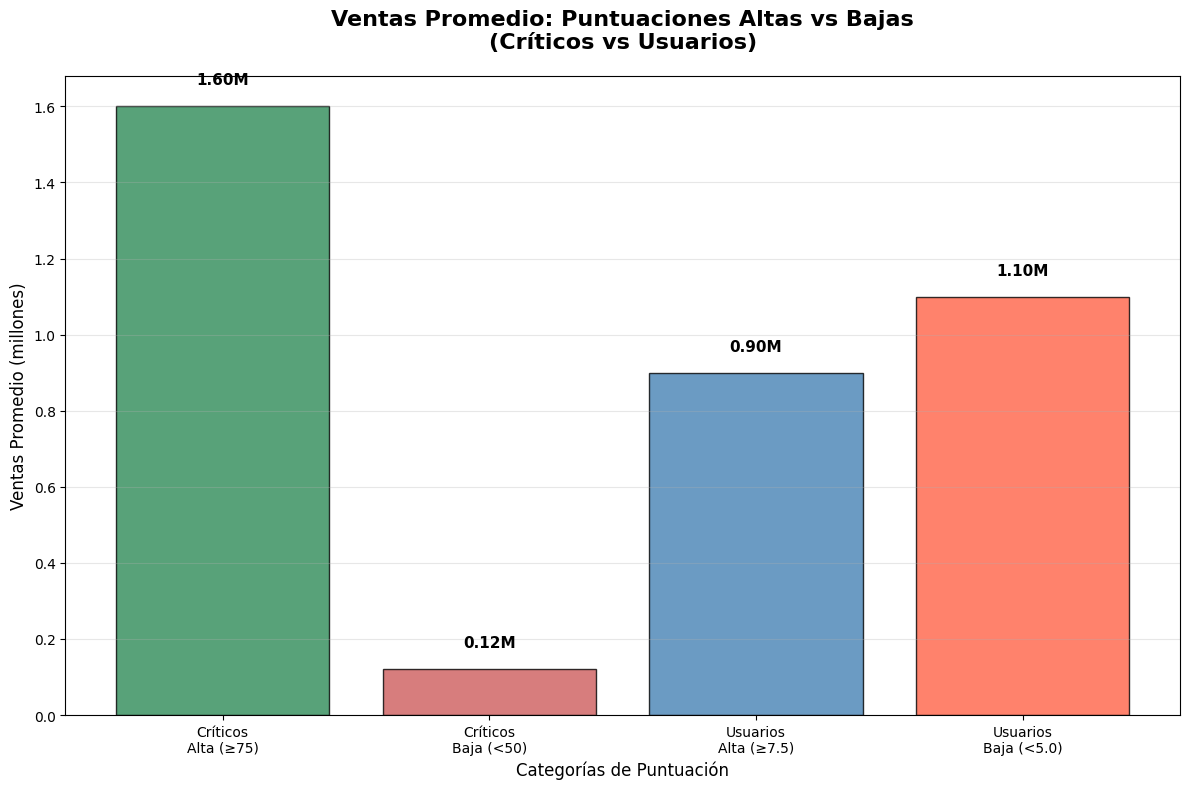

In [ ]:
categorias = ['Críticos\nAlta (≥75)', 'Críticos\nBaja (<50)', 
              'Usuarios\nAlta (≥7.5)', 'Usuarios\nBaja (<5.0)']
ventas_promedio = [1.60, 0.12, 0.90, 1.10]
colores = ['#2E8B57', '#CD5C5C', '#4682B4', '#FF6347']  # Verde, Rojo, Azul, Naranja

# Crear el gráfico
plt.figure(figsize=(12, 8))
barras = plt.bar(categorias, ventas_promedio, color=colores, alpha=0.8, edgecolor='black')

plt.title('Ventas Promedio: Puntuaciones Altas vs Bajas\n(Críticos vs Usuarios)', 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Ventas Promedio (millones)', fontsize=12)
plt.xlabel('Categorías de Puntuación', fontsize=12)

# Añadir valores encima de cada barra
for i, barra in enumerate(barras):
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2., altura + 0.05,
             f'{ventas_promedio[i]:.2f}M', ha='center', va='bottom', 
             fontweight='bold', fontsize=11)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Filtrar datos de PS4 con información completa
ps4_completo = video_juegos[
    (video_juegos['platform'] == 'PS4') & 
    (video_juegos['user_score'].notna()) & 
    (video_juegos['critic_score'] != 'unknown') & 
    (video_juegos['total_sales'] > 0)
].copy()

# Convertir critic_score a numérico
ps4_completo['critic_score'] = pd.to_numeric(ps4_completo['critic_score'])

print(f"Juegos de PS4 con datos completos: {len(ps4_completo)}")
print(f"Rango de años: {ps4_completo['year_of_release'].min()} - {ps4_completo['year_of_release'].max()}")

# Calcular correlaciones
correlacion_usuarios = ps4_completo['user_score'].corr(ps4_completo['total_sales'])
correlacion_criticos = ps4_completo['critic_score'].corr(ps4_completo['total_sales'])

print(f"Correlación User Score vs Ventas: {correlacion_usuarios:.3f}")
print(f"Correlación Critic Score vs Ventas: {correlacion_criticos:.3f}")

Juegos de PS4 con datos completos: 249
Rango de años: 2013 - 2016
Correlación User Score vs Ventas: -0.034
Correlación Critic Score vs Ventas: 0.406


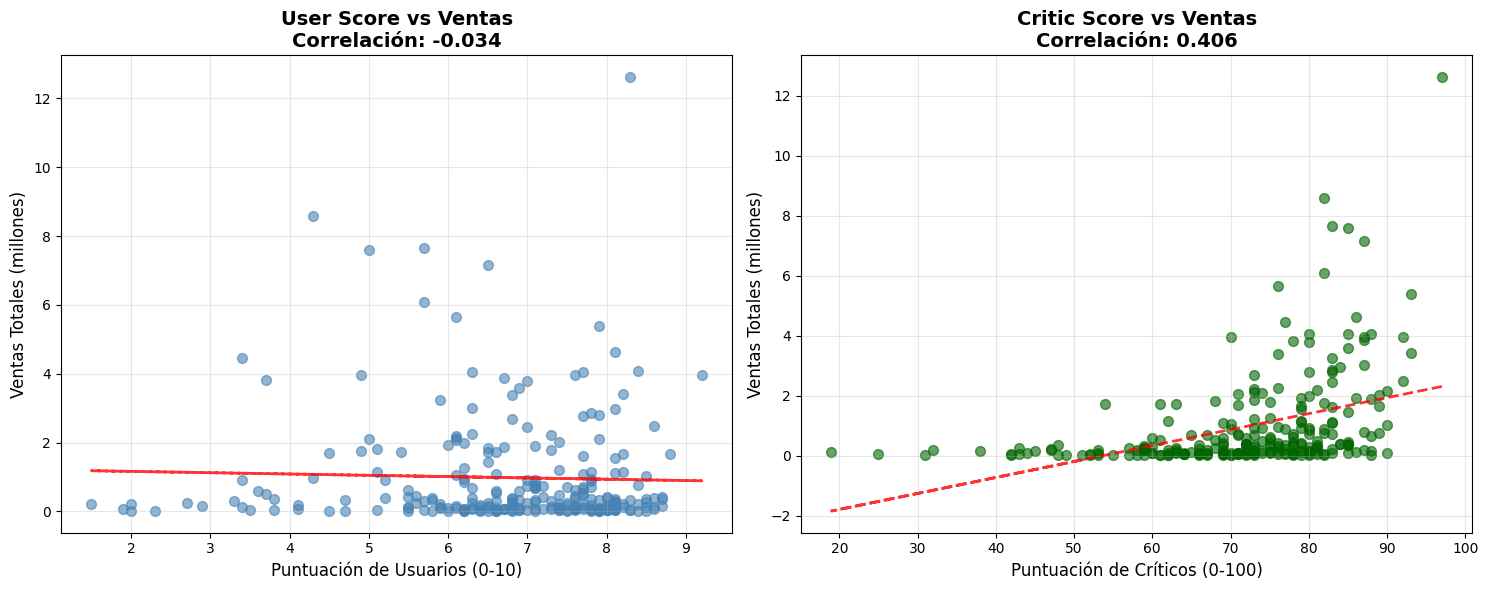

In [ ]:
# Crear gráficos de dispersión
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: User Score vs Ventas
ax1.scatter(ps4_completo['user_score'], ps4_completo['total_sales'], 
           alpha=0.6, color='steelblue', s=50)
ax1.set_xlabel('Puntuación de Usuarios (0-10)', fontsize=12)
ax1.set_ylabel('Ventas Totales (millones)', fontsize=12)
ax1.set_title(f'User Score vs Ventas\nCorrelación: {correlacion_usuarios:.3f}', 
             fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Línea de tendencia para User Score
z1 = np.polyfit(ps4_completo['user_score'], ps4_completo['total_sales'], 1)
p1 = np.poly1d(z1)
ax1.plot(ps4_completo['user_score'], p1(ps4_completo['user_score']), 
         "r--", alpha=0.8, linewidth=2)

# Gráfico 2: Critic Score vs Ventas
ax2.scatter(ps4_completo['critic_score'], ps4_completo['total_sales'], 
           alpha=0.6, color='darkgreen', s=50)
ax2.set_xlabel('Puntuación de Críticos (0-100)', fontsize=12)
ax2.set_ylabel('Ventas Totales (millones)', fontsize=12)
ax2.set_title(f'Critic Score vs Ventas\nCorrelación: {correlacion_criticos:.3f}', 
             fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

# Línea de tendencia para Critic Score
z2 = np.polyfit(ps4_completo['critic_score'], ps4_completo['total_sales'], 1)
p2 = np.poly1d(z2)
ax2.plot(ps4_completo['critic_score'], p2(ps4_completo['critic_score']), 
         "r--", alpha=0.8, linewidth=2)

plt.tight_layout()
plt.show()

## La correlacion de usuarios es practicamente 0, pero ligeramente negativa, esto puede significar que las ventas no estan predecidas por las reseñas, y es algo pequeño pero presente la tendencia de que los juegos con mejor reseña no tienen tan buenas ventas.

## La correlacion de los criticos es ligeramente positiva, lo que podemos deducir es que cuando los criticos califican mejor un juego tiene mejores ventas, es una relacion significativa. 

In [ ]:
# Análisis general de géneros
print("=== ANÁLISIS DE DISTRIBUCIÓN POR GÉNERO ===\n")

# 1. Cantidad de juegos por género
juegos_por_genero = video_juegos['genre'].value_counts()
print("Cantidad de juegos por género:")
print(juegos_por_genero.head(10))

# 2. Ventas totales por género
ventas_por_genero = video_juegos.groupby('genre')['total_sales'].sum().sort_values(ascending=False)
print(f"\nVentas totales por género (millones):")
print(ventas_por_genero.head(10))

# 3. Ventas promedio por género
ventas_promedio_genero = video_juegos.groupby('genre')['total_sales'].mean().sort_values(ascending=False)
print(f"\nVentas promedio por género (millones):")
print(ventas_promedio_genero.head(10))

=== ANÁLISIS DE DISTRIBUCIÓN POR GÉNERO ===

Cantidad de juegos por género:
Action          3369
Sports          2348
Misc            1750
Role-Playing    1498
Shooter         1323
Adventure       1303
Racing          1249
Platform         888
Simulation       873
Fighting         849
Name: genre, dtype: int64

Ventas totales por género (millones):
genre
Action          1744.17
Sports          1331.27
Shooter         1052.45
Role-Playing     934.56
Platform         827.77
Misc             802.51
Racing           728.67
Fighting         447.53
Simulation       389.97
Puzzle           242.57
Name: total_sales, dtype: float64

Ventas promedio por género (millones):
genre
Platform        0.932173
Shooter         0.795503
Role-Playing    0.623872
Racing          0.583403
Sports          0.566980
Fighting        0.527126
Action          0.517711
Misc            0.458577
Simulation      0.446701
Puzzle          0.418224
Name: total_sales, dtype: float64


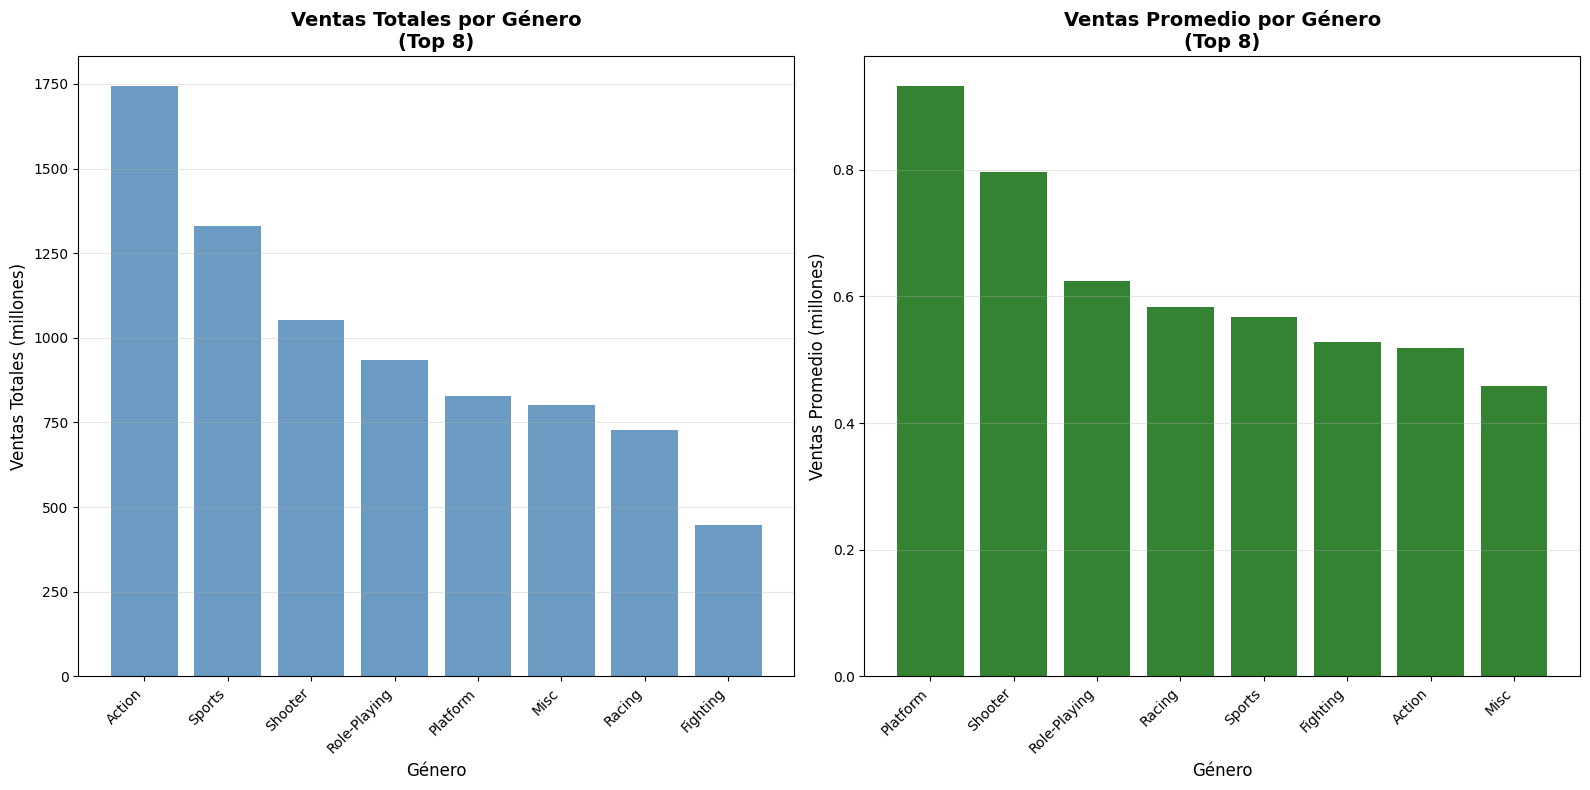

In [ ]:
# Crear gráfico comparativo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Gráfico 1: Ventas totales por género (Top 8)
top_8_generos = ventas_por_genero.head(8)
ax1.bar(range(len(top_8_generos)), top_8_generos.values, color='steelblue', alpha=0.8)
ax1.set_xlabel('Género', fontsize=12)
ax1.set_ylabel('Ventas Totales (millones)', fontsize=12)
ax1.set_title('Ventas Totales por Género\n(Top 8)', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(top_8_generos)))
ax1.set_xticklabels(top_8_generos.index, rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3)

# Gráfico 2: Ventas promedio por género (Top 8)
top_8_promedio = ventas_promedio_genero.head(8)
ax2.bar(range(len(top_8_promedio)), top_8_promedio.values, color='darkgreen', alpha=0.8)
ax2.set_xlabel('Género', fontsize=12)
ax2.set_ylabel('Ventas Promedio (millones)', fontsize=12)
ax2.set_title('Ventas Promedio por Género\n(Top 8)', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(top_8_promedio)))
ax2.set_xticklabels(top_8_promedio.index, rotation=45, ha='right')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Los generos mas populares son los de accion, seguidos por los shooter y los deportes, puedo pensar que los generos "seguros" son accion y deportes, con muchos titulos pero con una rentavilidad promedio, los generos "premium" plataform y shotter tienen pocos titulos pero mucho exito.

## Paso 4 perfil de usuario para cada region 

In [ ]:
video_juegos.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,año_ausente,user_score_was_tbd,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,False,False,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,unknown,NaN,unknown,False,False,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,False,False,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,False,False,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,unknown,NaN,unknown,False,False,31.38


In [ ]:
top_5_platforms = ['PS2', 'X360', 'PS3', 'Wii', 'DS']
top_platforms_data = video_juegos[video_juegos['platform'].isin(top_5_platforms)]

# Agrupar por plataforma y sumar ventas por región
platforms_by_region = top_platforms_data.groupby('platform')[['na_sales', 'eu_sales', 'jp_sales']].sum()

print("Ventas de las top 5 plataformas por región:")
print(platforms_by_region)

Ventas de las top 5 plataformas por región:
          na_sales  eu_sales  jp_sales
platform                              
DS          382.40    188.89    175.57
PS2         583.84    339.29    139.20
PS3         393.49    330.29     80.19
Wii         496.90    262.21     69.33
X360        602.47    270.76     12.43


### X360 domina por completo en Norte America, pero su presencia en japon es casi nula, Wii esta muy preente en Norte America pero curiosamente en Japon no es muy popular, PS2 domina en Norte America, pero esta bajo en Japon, DS esta muy equilibrado en Japon y Europa.

In [ ]:
# Calcular totales por región para estas 5 plataformas
region_totals = platforms_by_region.sum()
print("Totales por región:")
print(region_totals)

# Calcular cuotas de mercado (porcentajes)
market_share = platforms_by_region.div(region_totals) * 100
print("\nCuotas de mercado por región (%):")
print(market_share.round(2))

Totales por región:
na_sales    2459.10
eu_sales    1391.44
jp_sales     476.72
dtype: float64

Cuotas de mercado por región (%):
          na_sales  eu_sales  jp_sales
platform                              
DS           15.55     13.58     36.83
PS2          23.74     24.38     29.20
PS3          16.00     23.74     16.82
Wii          20.21     18.84     14.54
X360         24.50     19.46      2.61


In [ ]:
video_juegos['rating'].value_counts()

unknown    6766
E          3990
T          2961
M          1563
E10+       1420
EC            8
K-A           3
RP            3
AO            1
Name: rating, dtype: int64

In [ ]:
juegos_filtrados = video_juegos[(video_juegos['year_of_release'] >= 2013) & 
                                (video_juegos['year_of_release'] <= 2016)]
print(f"Juegos después del filtro: {len(juegos_filtrados)}")
ventas_por_rating = juegos_filtrados.groupby('rating')[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].sum()
print(ventas_por_rating)

Juegos después del filtro: 2233
         na_sales  eu_sales  jp_sales  other_sales
rating                                            
E           79.05     83.36     15.14        22.61
E10+        54.24     42.69      5.89        12.57
M          165.21    145.32     14.11        47.04
T           49.79     41.95     20.59        14.29
unknown     89.42     78.91     85.05        23.46


Ventas por género y región (Top 8 géneros):
              na_sales  eu_sales  jp_sales
genre                                     
Action          879.01    519.13    161.43
Sports          684.43    376.79    135.54
Shooter         592.24    317.34     38.76
Role-Playing    330.81    188.71    355.41
Platform        445.50    200.35    130.83
Misc            407.27    212.74    108.11
Racing          359.35    236.51     56.71
Fighting        223.36    100.33     87.48


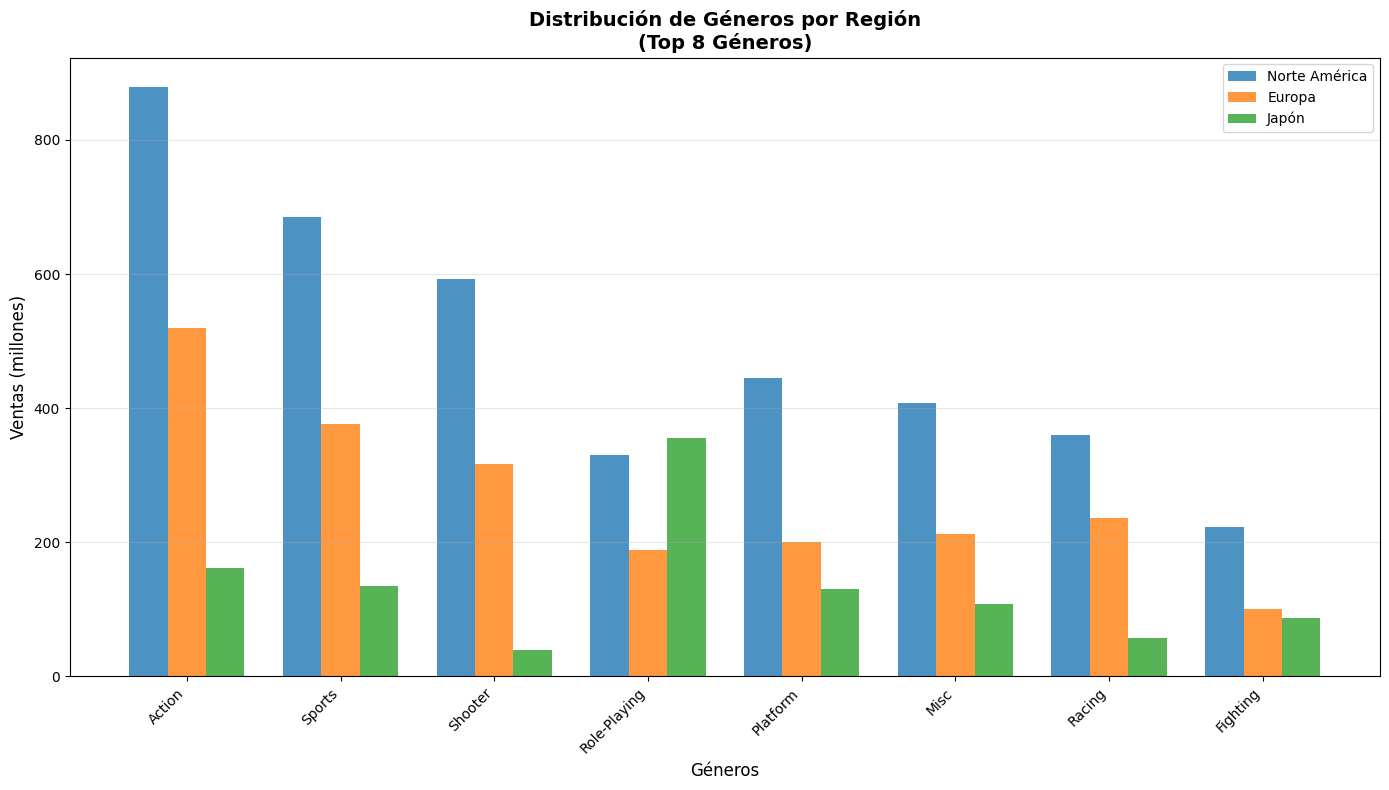

In [ ]:
# Crear un análisis de géneros por región
generos_por_region = video_juegos.groupby('genre')[['na_sales', 'eu_sales', 'jp_sales']].sum()

# Seleccionar los top 8 géneros por ventas totales para mejor visualización
top_generos = video_juegos.groupby('genre')['total_sales'].sum().sort_values(ascending=False).head(8)
generos_filtrados = generos_por_region.loc[top_generos.index]

print("Ventas por género y región (Top 8 géneros):")
print(generos_filtrados.round(2))

# Datos ya preparados de géneros por región (Top 8 géneros)
generos = ['Action', 'Sports', 'Shooter', 'Role-Playing', 'Platform', 'Misc', 'Racing', 'Fighting']
na_sales = [879.01, 684.43, 592.24, 330.81, 445.50, 407.27, 359.35, 223.36]
eu_sales = [519.13, 376.79, 317.34, 188.71, 200.35, 212.74, 236.51, 100.33]
jp_sales = [161.43, 135.54, 38.76, 355.41, 130.83, 108.11, 56.71, 87.48]

# Configurar el gráfico
fig, ax = plt.subplots(figsize=(14, 8))

# Configurar posiciones de las barras
x = np.arange(len(generos))
width = 0.25

# Crear barras agrupadas con colores distintivos
bars1 = ax.bar(x - width, na_sales, width, label='Norte América', color='#1f77b4', alpha=0.8)
bars2 = ax.bar(x, eu_sales, width, label='Europa', color='#ff7f0e', alpha=0.8)
bars3 = ax.bar(x + width, jp_sales, width, label='Japón', color='#2ca02c', alpha=0.8)

# Personalizar el gráfico
ax.set_xlabel('Géneros', fontsize=12)
ax.set_ylabel('Ventas (millones)', fontsize=12)
ax.set_title('Distribución de Géneros por Región\n(Top 8 Géneros)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(generos, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### La clasificacion M es la mas popular en Norte America y en Europa pero en Japon es la E, recordemos que unknown son juegos publicados antes de 1994, y el mercado retro es popular tambien en Japon

## Paso 5 pruebas de hipotesis 

## Hipotesis 1: Las caliicaciones promedio de usuarios para Xbox One y PC son las mismas 
## Hipotesis 2: Las caliicaciones promedio de usuarios para genenros de accion y deportes son diferentes 

In [ ]:
# filtrado de datos para la primera hipotesis
# H₀: μ_XboxOne = μ_PC (las calificaciones promedio son iguales)
# H₁: μ_XboxOne ≠ μ_PC (las calificaciones promedio son diferentes

# filtrado para xboxone 
xbox_score = video_juegos[video_juegos ['platform'] == 'XOne']['user_score']

# filtrado para PC
pc_score = video_juegos[video_juegos ['platform'] == 'PC']['user_score']

print(xbox_score)
print(pc_score)

99       NaN
165      7.9
179      5.4
242      6.4
270      6.2
        ... 
16630    8.2
16643    6.6
16645    NaN
16660    6.7
16672    NaN
Name: user_score, Length: 247, dtype: float64
85       7.6
138      7.3
192      4.0
195      NaN
218      8.2
        ... 
16690    NaN
16692    7.6
16696    5.8
16702    7.2
16705    5.8
Name: user_score, Length: 974, dtype: float64


In [ ]:
#(asegúrarse de que no haya valores nulos)
xbox_scores = video_juegos[video_juegos['platform'] == 'XOne']['user_score'].dropna()
pc_scores = video_juegos[video_juegos['platform'] == 'PC']['user_score'].dropna()

alpha = 0.05

# Prueba t para dos muestras independientes
resultado = st.ttest_ind(xbox_scores, pc_scores)

print(f'Valor p: {resultado.pvalue}')

Valor p: 1.3896435533548819e-05


In [ ]:
# Filtrar datos (sin valores nulos)
xbox_scores = video_juegos[video_juegos['platform'] == 'XOne']['user_score'].dropna()
pc_scores = video_juegos[video_juegos['platform'] == 'PC']['user_score'].dropna()

print(f"Muestra Xbox One: {len(xbox_scores)} juegos")
print(f"Muestra PC: {len(pc_scores)} juegos")

# PASO 1: Prueba de Levene para igualdad de varianzas
levene_stat, levene_p = st.levene(xbox_scores, pc_scores)  # Usando st.levene
print(f"\n=== PRUEBA DE LEVENE ===")
print(f"Estadístico de Levene: {levene_stat:.4f}")
print(f"Valor p de Levene: {levene_p:.6f}")

# Interpretar resultado de Levene
alpha = 0.05
if levene_p < alpha:
    equal_variances = False
    print("→ Las varianzas son DIFERENTES (rechazamos H₀)")
else:
    equal_variances = True
    print("→ Las varianzas son IGUALES (no rechazamos H₀)")

# PASO 2: Prueba t con el parámetro correcto
resultado = st.ttest_ind(xbox_scores, pc_scores, equal_var=equal_variances)
print(f"\n=== PRUEBA T ===")
print(f"Estadístico t: {resultado.statistic:.4f}")
print(f"Valor p: {resultado.pvalue:.6f}")

# Interpretar resultado
if resultado.pvalue < alpha:
    print("→ RECHAZAMOS H₀: Las calificaciones promedio SÍ son diferentes")
else:
    print("→ NO RECHAZAMOS H₀: No hay evidencia de diferencia significativa")

Muestra Xbox One: 182 juegos
Muestra PC: 770 juegos

=== PRUEBA DE LEVENE ===
Estadístico de Levene: 1.2213
Valor p de Levene: 0.269395
→ Las varianzas son IGUALES (no rechazamos H₀)

=== PRUEBA T ===
Estadístico t: -4.3683
Valor p: 0.000014
→ RECHAZAMOS H₀: Las calificaciones promedio SÍ son diferentes


## Conclucion las calificaciones promedio de Xbox One y PC SÍ son significativamente diferentes.

In [ ]:
# filtrado de datos para la segundo hipotesis
# H₀: μ_accion = μ_deportes (las calificaciones promedio son iguales)
# H₁: μ_accion ≠ μ_deporte (las calificaciones promedio son diferentes

# filtrado para accion
xbox_score = video_juegos[video_juegos ['genre'] == 'Action']['user_score']

# filtrado para deportes
pc_score = video_juegos[video_juegos ['genre'] == 'Sports']['user_score']

print(xbox_score)
print(pc_score)

16       8.2
17       9.0
23       8.1
24       8.7
38       8.5
        ... 
16692    7.6
16694    NaN
16695    NaN
16699    NaN
16710    NaN
Name: user_score, Length: 3369, dtype: float64
0        8.0
3        8.0
13       7.7
15       7.4
77       4.3
        ... 
16676    NaN
16688    NaN
16693    NaN
16700    NaN
16711    NaN
Name: user_score, Length: 2348, dtype: float64


In [ ]:

#(asegúrarse de que no haya valores nulos)

accion_scores = video_juegos[video_juegos['genre'] == 'Action']['user_score'].dropna()
sports_scores = video_juegos[video_juegos['genre'] == 'Sports']['user_score'].dropna()

alpha = 0.05

# Prueba t para dos muestras independientes
resultado = st.ttest_ind(accion_scores, sports_scores)

print(f'Valor p: {resultado.pvalue}')



Valor p: 0.10406951359049141


In [ ]:
# Filtrar datos para géneros (sin valores nulos)
accion_scores = video_juegos[video_juegos['genre'] == 'Action']['user_score'].dropna()
sports_scores = video_juegos[video_juegos['genre'] == 'Sports']['user_score'].dropna()

print(f"Muestra Acción: {len(accion_scores)} juegos")
print(f"Muestra Deportes: {len(sports_scores)} juegos")

# PASO 1: Prueba de Levene para igualdad de varianzas
levene_stat, levene_p = st.levene(accion_scores, sports_scores)
print(f"\n=== PRUEBA DE LEVENE ===")
print(f"Estadístico de Levene: {levene_stat:.4f}")
print(f"Valor p de Levene: {levene_p:.6f}")

# Interpretar resultado de Levene
alpha = 0.05
if levene_p < alpha:
    equal_variances = False
    print("→ Las varianzas son DIFERENTES (rechazamos H₀)")
else:
    equal_variances = True
    print("→ Las varianzas son IGUALES (no rechazamos H₀)")

# PASO 2: Prueba t con el parámetro correcto
resultado = st.ttest_ind(accion_scores, sports_scores, equal_var=equal_variances)
print(f"\n=== PRUEBA T ===")
print(f"Estadístico t: {resultado.statistic:.4f}")
print(f"Valor p: {resultado.pvalue:.6f}")

# Interpretar resultado
if resultado.pvalue < alpha:
    print("→ RECHAZAMOS H₀: Las calificaciones promedio SÍ son diferentes")
else:
    print("→ NO RECHAZAMOS H₀: No hay evidencia de diferencia significativa")

Muestra Acción: 1830 juegos
Muestra Deportes: 1103 juegos

=== PRUEBA DE LEVENE ===
Estadístico de Levene: 14.1329
Valor p de Levene: 0.000174
→ Las varianzas son DIFERENTES (rechazamos H₀)

=== PRUEBA T ===
Estadístico t: 1.5775
Valor p: 0.114838
→ NO RECHAZAMOS H₀: No hay evidencia de diferencia significativa


## Conclucion No rechazamos la hipotesis nula, mo hay evidencia suficiente para decir que hay diferencia significactivamente entre los grupos.


### Para formular mis hipotesis primero filtre el dataset usando las columnas 'platform', 'XOne', 'PC' y 'user_score' para obtener la muestra, filtrelos datos para dejarlos sin valores nulos y establci un valor alpha 0.05 que es mas comun para hacer las compoaraciones con una prueba de hipotesis con valores P (muestras filtradas), y el procedimiento fue el mismo para lcomparacion entre generos usando las columnas 'genre', 'Action', 'Sport' y 'user_score'.

## Conclucion del analisis para 2017, apostaria por las consolas de Sony y Micrsoft en el mercado americano y europeo, y le daria un seguimiento especial a Nintendo esperando siga con tendencias constantes y firmes en el mercado, es muy robable qque mantenga sus numeros.